# ConnectaTel: Calidad de datos y segmentación de clientes

**Caso de negocio simulado del bootcamp de Data Analytics de TripleTen.** Los datos son ficticios.

**Pregunta de negocio:** ¿cómo se comportan los clientes de una empresa de telecomunicaciones en Latinoamérica y cómo se pueden segmentar para mejorar sus planes?

**Datos:** tres datasets: planes (2), usuarios (4,000) y registros de uso (40,000), con información hasta 2024.

**Herramientas:** Python (pandas, NumPy, seaborn, Matplotlib).

**Hallazgos principales**
1. Los datos tenían dos sentinels (`-999` en edad y `?` en ciudad) y fechas fuera del periodo de análisis, que se trataron antes de analizar.
2. Predominan los adultos con uso medio; los clientes de alto uso son pocos, pero estratégicos.
3. No se observan diferencias de uso entre los planes Básico y Premium, lo que sugiere que Premium no se diferencia lo suficiente.

---
## 🧩 Paso 1: Cargar y explorar

### 1.1 Carga de datos y vista rápida

In [ ]:
# importar librerías
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

In [ ]:
# cargar archivos
plans = pd.read_csv('/datasets/plans.csv')
users = pd.read_csv('/datasets/users_latam.csv')
usage = pd.read_csv('/datasets/usage.csv')

In [ ]:
# mostrar las primeras 5 filas de plans
plans.head()

,plan_name,messages_included,gb_per_month,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
0,Basico,100,5,100,12,1.2,0.08,0.10
1,Premium,500,20,600,25,1.0,0.05,0.07


In [ ]:
# mostrar las primeras 5 filas de users
users.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


In [ ]:
# mostrar las primeras 5 filas de usage
usage.head()

,id,user_id,type,date,duration,length
0,1,10332,call,2024-01-01 00:00:00.000000000,0.09,NaN
1,2,11458,text,2024-01-01 00:06:30.969774244,NaN,39.0
2,3,11777,text,2024-01-01 00:13:01.939548488,NaN,36.0
3,4,10682,call,2024-01-01 00:19:32.909322733,1.53,NaN
4,5,12742,call,2024-01-01 00:26:03.879096977,4.84,NaN


### 1.2 Exploración de la estructura de los datasets

In [ ]:
# revisar el número de filas y columnas de cada dataset
print("plans", plans.shape)
print("users", users.shape)
print("usage", usage.shape)

plans (2, 8)
users (4000, 8)
usage (40000, 6)


In [ ]:
# inspección de plans con .info()
plans.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 256.0+ bytes


In [ ]:
# inspección de users con .info()
users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  4000 non-null   object
 2   last_name   4000 non-null   object
 3   age         4000 non-null   int64 
 4   city        3531 non-null   object
 5   reg_date    4000 non-null   object
 6   plan        4000 non-null   object
 7   churn_date  466 non-null    object
dtypes: int64(2), object(6)
memory usage: 250.1+ KB


In [ ]:
# inspección de usage con .info()
usage.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        40000 non-null  int64  
 1   user_id   40000 non-null  int64  
 2   type      40000 non-null  object 
 3   date      39950 non-null  object 
 4   duration  17924 non-null  float64
 5   length    22104 non-null  float64
dtypes: float64(2), int64(2), object(2)
memory usage: 1.8+ MB


---

## 🧩Paso 2: Identificación de problemas de calidad de datos

### 2.1 Revisión de valores nulos

In [ ]:
# cantidad de nulos para users
print(users.isna().sum())
print(users.isna().mean())

user_id          0
first_name       0
last_name        0
age              0
city           469
reg_date         0
plan             0
churn_date    3534
dtype: int64
user_id       0.00000
first_name    0.00000
last_name     0.00000
age           0.00000
city          0.11725
reg_date      0.00000
plan          0.00000
churn_date    0.88350
dtype: float64


In [ ]:
# cantidad de nulos para usage
print(usage.isna().sum())
print(usage.isna().mean())

id              0
user_id         0
type            0
date           50
duration    22076
length      17896
dtype: int64
id          0.00000
user_id     0.00000
type        0.00000
date        0.00125
duration    0.55190
length      0.44740
dtype: float64


#Diagnóstico

 ---

**Valores nulos**  
- - ¿Qué columnas tienen valores faltantes y en qué proporción?
- En la tabla USERS, la columna CITY presenta 469 valores faltantes en proporción de 11.73%. Y la columna CHURN_DATE presenta 3,534 valores faltantes en proporción del 88.35%.
- En la tabla USAGE, la columna DATE presenta 50 valores faltantes (0.13%); DURATION contiene 22,076 valores faltantes (55.19%); y LENGTH presenta 17,896 valores faltantes (44.74%).

  
- - Indica qué harías: ¿imputar, eliminar, ignorar?
- users.city: Mantener e imputar como "Desconocida" (o excluir solo en análisis por ciudad).
Es una variable categórica. El porcentaje no es excesivamente alto y eliminar esos usuarios podría sesgar los análisis geográficos.
- users.churn_date: No imputar ni eliminar. Mantener los nulos.
En telecomunicaciones, un valor nulo normalmente significa que el cliente sigue activo. Es información útil y coherente con la lógica del negocio.
- usage.date: Eliminar esos registros o recuperarlos si existe otra fuente.
El porcentaje es mínimo y no afectará significativamente el análisis.
- usage.duration: Mantener los nulos inicialmente y analizar según el tipo de uso.
La duración suele existir únicamente para llamadas. Si el registro corresponde a SMS o Internet, el nulo es esperado y no debe imputarse.
- usage.length: Mantener los nulos inicialmente y analizar según su tipo.
La longitud generalmente aplica a SMS, pero no a llamadas. Es probable que los nulos sean válidos y dependan del tipo de evento.

### 2.2 Detección de valores inválidos y sentinels

In [ ]:
# explorar columnas numéricas de users
print(users[['user_id', 'age']].describe())

            user_id          age
count   4000.000000  4000.000000
mean   11999.500000    33.739750
std     1154.844867   123.232257
min    10000.000000  -999.000000
25%    10999.750000    32.000000
50%    11999.500000    47.000000
75%    12999.250000    63.000000
max    13999.000000    79.000000


- La columna `user_id` presenta 4,000 registros, sin valores faltantes. Los identificadores van desde 10,000 hasta 13,999, con una media de 11,999.5 y una distribución uniforme, lo que indica que se trata de un identificador único de los usuarios y no de una variable útil para realizar análisis estadísticos o de comportamiento.
- La columna `age` también cuenta con 4,000 registros, por lo que no presenta valores nulos. Sin embargo, se observa un valor mínimo de -999, el cual es imposible para una edad y claramente corresponde a un valor erróneo o un código utilizado para representar datos faltantes. La distribución de la edad muestra que el 50% de los usuarios tiene 47 años o menos (mediana = 47). Además, el 25% tiene 32 años o menos, mientras que el 75% tiene 63 años o menos, lo que indica una población con una amplia diversidad de edades.
La desviación estándar de 123.23 años es excesivamente alta para una variable de edad y está claramente influenciada por el valor atípico -999. Sin este dato erróneo, la dispersión sería mucho menor y las estadísticas descriptivas serían más representativas.

In [ ]:
# explorar columnas numéricas de usage
print(usage[['id', 'user_id', 'duration', 'length']].describe())

                id       user_id      duration        length
count  40000.00000  40000.000000  17924.000000  22104.000000
mean   20000.50000  12002.405975      5.202237     52.127398
std    11547.14972   1157.279564      6.842701     56.611183
min        1.00000  10000.000000      0.000000      0.000000
25%    10000.75000  10996.000000      1.437500     37.000000
50%    20000.50000  12013.000000      3.500000     50.000000
75%    30000.25000  13005.000000      6.990000     64.000000
max    40000.00000  13999.000000    120.000000   1490.000000




- Las columnas `id` y `user_id` contienen 40,000 registros, sin valores nulos. En `id`, los valores van desde 1 hasta 40,000, con una media de 20,000.5, lo que indica que corresponde a un identificador único para cada registro de uso. En `user_id`, los identificadores se encuentran entre 10,000 y 13,999, coincidiendo con el rango observado en la tabla USERS, lo que confirma la consistencia entre ambas tablas y permitiría relacionarlas mediante esta clave.
La distribución de `user_id` es equilibrada, con una media de 12,002.41 y percentiles distribuidos de forma uniforme.
- Las columnas `duration` y `length` presentan una cantidad importante de valores faltantes, aunque esto probablemente se deba a que cada una aplica a un tipo específico de uso. Entre los registros válidos, ambas variables muestran distribuciones razonables. No obstante, destaca el valor máximo de 1,490 en `length`, que podría constituir un valor atípico y debería analizarse mediante gráficos para determinar si corresponde a un comportamiento real o a un error en los datos. La columna `duration` cuenta con 17,924 registros válidos, lo que confirma la presencia de valores faltantes observada anteriormente. La duración promedio de los eventos es de 5.20 minutos, con una mediana de 3.50 minutos, lo que indica que la mayoría de las llamadas son relativamente cortas. El valor máximo es de 120 minutos, mientras que la desviación estándar (6.84 minutos) evidencia una variabilidad considerable, probablemente debido a la existencia de algunas llamadas de larga duración. La columna `length` dispone de 22,104 registros válidos. La longitud promedio es de 52.13 unidades (caracteres, si corresponde a mensajes), con una mediana de 50, muy cercana a la media, lo que sugiere una distribución relativamente simétrica. El máximo registrado es de 1,490, un valor considerablemente superior al resto de los datos que podría representar un mensaje excepcionalmente largo o un posible valor atípico que conviene revisar.



In [ ]:
# explorar columnas categóricas de users
columnas_user = ['city', 'plan']
print(users[columnas_user].describe())

          city    plan
count     3531    4000
unique       7       2
top     Bogotá  Basico
freq       808    2595


- La columna `city` cuenta con 3,531 registros válidos, lo que confirma la existencia de 469 valores faltantes (11.73%) identificados previamente. Se registran 7 ciudades diferentes, siendo Bogotá la más frecuente, con 808 usuarios.
- La columna `plan` presenta 4,000 registros completos, sin valores nulos. Existen únicamente 2 tipos de planes, siendo Básico el más contratado, con 2,595 usuarios, lo que representa aproximadamente el 64.9% del total de clientes.

In [ ]:
# explorar columna categórica de usage
print(usage[['type']].describe())

         type
count   40000
unique      2
top      text
freq    22092


- La columna `type` cuenta con 40,000 registros, por lo que no presenta valores faltantes, lo que garantiza la integridad de esta información para los análisis. Se identifican 2 categorías únicas y la categoría más frecuente es text, con 22,092 registros, lo que representa aproximadamente el 55.2% del total de eventos.


---
#Diagnóstico

**Valores inválidos o sentinels**  
- - ¿En qué columnas encontraste valores inválidos o sentinels?
- Se identificaron dos sentinels: -999 en `age` y ? en `city` (96 registros). El -999 se reemplazó por la mediana de age y los ? se convirtieron en nulos.
- - ¿Qué acción tomarías?
- Creo que debe reemplazarse por NaN antes de su tratamiento para evitar sesgos en el análisis.

### 2.3 Revisión y estandarización de fechas

In [ ]:
# Convertir a fecha la columna `reg_date` de users
users['reg_date'] = pd.to_datetime(users['reg_date'], errors='coerce', utc=True)
users['reg_date'].dtype

datetime64[ns, UTC]

In [ ]:
# Convertir a fecha la columna `date` de usage
usage['date'] = pd.to_datetime(usage['date'], errors='coerce', utc=True)
usage['date'].dtype

datetime64[ns, UTC]

In [ ]:
# Revisar los años presentes en `reg_date` de users
users['reg_date'].dt.year.unique()

array([2022, 2026, 2023, 2024])

- En `reg_date`, se encuentran los siguientes años: 2022, 2023, 2024 y 2026.

In [ ]:
# Revisar los años presentes en `date` de usage
usage['date'].dt.year.unique()

array([2024.,   nan])

En `date`, se encuentra el año 2024 y NaN.  
Basaremos el análisis en estas fechas.

#Diagnóstico

**Fechas fuera de rango**  
- - ¿Aparecen años imposibles? (años muy viejos o sin transcurrir al momento de guardar los datos)
- Sí: 40 registros de `users` tienen reg_date en 2026, posterior al periodo de análisis (hasta 2024), y se marcaron como NA. Además, 50 registros de `usage` (0.13%) no tienen fecha y se recomienda eliminarlos.

---

## 🧩Paso 3: Limpieza básica de datos

### 3.1 Corregir sentinels y fechas imposibles

In [ ]:
# Reemplazar -999 por la mediana de age
age_mediana = users['age'].median()
users['age'] = users['age'].replace(-999, age_mediana)

# Verificar cambios
users['age'].describe()

count    4000.000000
mean       48.122250
std        17.690408
min        18.000000
25%        33.000000
50%        47.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64

In [ ]:
# Reemplazar ? por NA en city
users['city'] = users['city'].replace('?', pd.NA)

# Verificar cambios
users['city'].describe()

count       3435
unique         6
top       Bogotá
freq         808
Name: city, dtype: object

In [ ]:
# Marcar fechas futuras como NA para reg_date
users.loc[users['reg_date'].dt.year == 2026, 'reg_date'] = pd.NA

# Verificar cambios
users['reg_date'].dt.year.value_counts()

2024.0    1330
2023.0    1316
2022.0    1314
Name: reg_date, dtype: int64

### 3.2 Corregir sentinels y fechas imposibles

In [ ]:
# Verificación MAR en usage (Missing At Random) para duration

MAR_duration = usage["duration"].isna().groupby(usage["type"]).mean()
print(MAR_duration)


type
call    0.000000
text    0.999276
Name: duration, dtype: float64


In [ ]:
# Verificación MAR en usage (Missing At Random) para length
MAR_length = usage["length"].isna().groupby(usage["type"]).mean()
print(MAR_length)


type
call    0.99933
text    0.00000
Name: length, dtype: float64


#Diagnóstico

- En la columna `duration` se observa que:
Para los registros de tipo `call`, la variable `duration` está prácticamente completa (0% de valores nulos). Para los registros de tipo `text`, casi todos los valores son nulos (99.93%), lo que indica que la duración no se registra para este tipo de evento. Los valores faltantes de `duration` dependen de la variable `type`, por lo que pueden considerarse MAR (Missing At Random) al estar explicados por una variable observada. Por ello, yo decidiría mantener los valores nulos y no realizar imputaciones ni eliminar registros, ya que reemplazarlos introduciría información ficticia y podría sesgar los análisis de consumo.
- En la columna `length` se observa que:
Para los registros de tipo `call`, la variable `length` presenta valores nulos en prácticamente todos los casos (99.93%). Para los registros de tipo `text`, no existen valores nulos, lo que indica que la longitud del mensaje se registra correctamente para este tipo de evento. Los valores faltantes de la variable `length` dependen de la variable `type`, ya que la longitud solo es relevante para los mensajes de texto y no para las llamadas. Esto confirma que los valores faltantes son MAR (Missing At Random), al estar condicionados por una variable observada. Por esta razón, se decidió conservar los valores nulos y no realizar imputaciones ni eliminar registros. Imputar valores en length para las llamadas generaría información artificial que no representa el comportamiento real de los usuarios y podría sesgar los resultados del análisis.

---

## 🧩Paso 4: Summary statistics de uso por usuario


### 4.1 Agrupación por comportamiento de uso

In [ ]:
# Columnas auxiliares
usage["is_text"] = (usage["type"] == "text").astype(int) #conocer el total de mensajes
usage["is_call"] = (usage["type"] == "call").astype(int) #conocer el total de llamadas


# Agrupar información por usuario
usage_agg = usage.groupby("user_id").agg({"is_text": "sum", "is_call": "sum", "duration": "sum"}).reset_index()

# observar resultado
usage_agg.head(3)

,user_id,is_text,is_call,duration
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [ ]:
# Renombrar columnas
usage_agg = usage_agg.rename(columns={"is_text": "cant_mensajes", "is_call": "cant_llamadas", "duration": "cant_minutos_llamada"})
# observar resultado
usage_agg.head(3)

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [ ]:
# Combinar la tabla agregada con el dataset de usuarios
user_profile = pd.merge(users, usage_agg, on = 'user_id', how='left')
user_profile.head(5)

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00+00:00,Basico,NaN,7.0,3.0,23.70
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619+00:00,Basico,NaN,5.0,10.0,33.18
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239+00:00,Basico,NaN,5.0,2.0,10.74
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858+00:00,Premium,NaN,11.0,3.0,8.99
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478+00:00,Basico,NaN,4.0,3.0,8.01


### 4.2 Resumen estadístico por usuario durante el 2024

In [ ]:
# Resumen estadístico de las columnas numéricas
columnas_numericas = ['user_id', 'age']
print(users[columnas_numericas].describe())

            user_id          age
count   4000.000000  4000.000000
mean   11999.500000    48.122250
std     1154.844867    17.690408
min    10000.000000    18.000000
25%    10999.750000    33.000000
50%    11999.500000    47.000000
75%    12999.250000    63.000000
max    13999.000000    79.000000


In [ ]:
# Distribución porcentual del tipo de plan
users_plan_basico = users[users['plan'] == "Basico"]
users_plan_premium = users[users['plan'] == "Premium"]

print("Distribución porcentual del plan Basico:")
print(users_plan_basico['plan'].describe())

print("Distribución porcentual del plan Premium:")
print(users_plan_premium['plan'].describe())

Distribución porcentual del plan Basico:
count       2595
unique         1
top       Basico
freq        2595
Name: plan, dtype: object
Distribución porcentual del plan Premium:
count        1405
unique          1
top       Premium
freq         1405
Name: plan, dtype: object


---

## 🧩Paso 5: Visualización de distribuciones (uso y clientes) y outliers


### 5.1 Visualización de Distribuciones

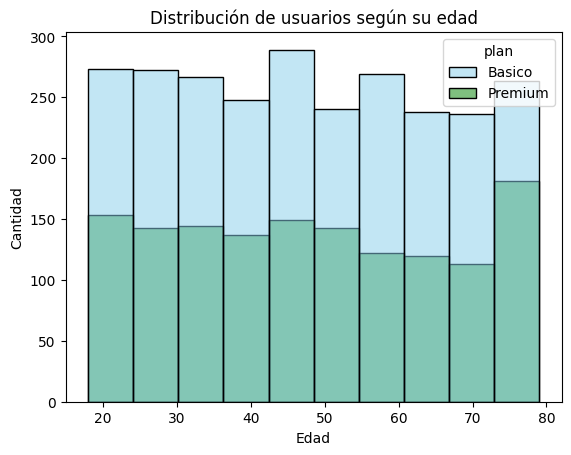

In [ ]:
# Histograma para visualizar la edad (age)
sns.histplot(users[['age', 'plan']], bins=10, hue='plan', palette=['skyblue','green'], x='age')
plt.xlabel('Edad')
plt.ylabel('Cantidad')
plt.title('Distribución de usuarios según su edad')
plt.show()

💡Insights:
- `Distribución de usuarios según su edad`:
Distribución relativamente uniforme entre los 18 y 80 años, sin asimetrías marcadas. Ambos planes presentan una distribución muy similar en todas las edades. El plan Básico tiene más usuarios porque concentra una mayor cantidad de clientes. La edad no parece ser un factor determinante en la elección del plan, ya que ambos planes se distribuyen de manera similar entre los distintos grupos.

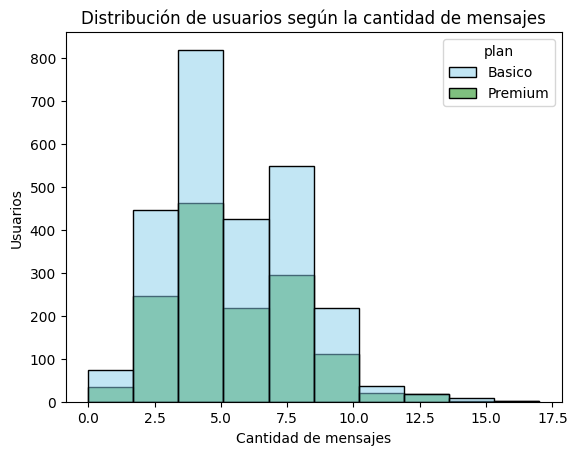

In [ ]:
# Histograma para visualizar la cant_mensajes
sns.histplot(user_profile[['cant_mensajes', 'plan']], bins=10, hue='plan', palette=['skyblue','green'], x='cant_mensajes')
plt.xlabel('Cantidad de mensajes')
plt.ylabel('Usuarios')
plt.title('Distribución de usuarios según la cantidad de mensajes')
plt.show()

💡Insights:
- `Distribución de usuarios según la cantidad de mensajes`:
Distribución unimodal con asimetría positiva (cola hacia la derecha). La mayoría de los usuarios envía pocos mensajes y pocos usuarios envían muchos.
El patrón es similar en ambos planes, aunque el plan Básico concentra un mayor número de usuarios en todos los niveles de uso. No se observa una diferencia clara en la forma de la distribución. El comportamiento de envío de mensajes es muy similar entre ambos planes, por lo que el tipo de plan no parece influir significativamente en la cantidad de mensajes enviados.

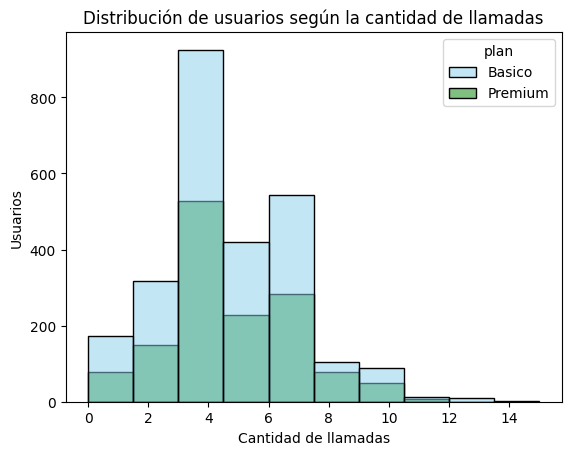

In [ ]:
# Histograma para visualizar la cant_llamadas
sns.histplot(user_profile[['cant_llamadas', 'plan']], bins=10, hue='plan', palette=['skyblue','green'], x='cant_llamadas')
plt.xlabel('Cantidad de llamadas')
plt.ylabel('Usuarios')
plt.title('Distribución de usuarios según la cantidad de llamadas')
plt.show()

💡Insights:
- `Distribución de usuarios según la cantidad de llamadas`:
Distribución unimodal con asimetría positiva. La mayor parte de los usuarios realiza entre 3 y 6 llamadas, mientras que pocos realizan muchas llamadas. Ambos planes presentan prácticamente la misma forma de distribución. El plan Básico registra más usuarios debido a su mayor tamaño muestral. Los clientes de ambos planes muestran patrones de llamadas similares, sin evidencia visual de que un plan incentive una mayor cantidad de llamadas.

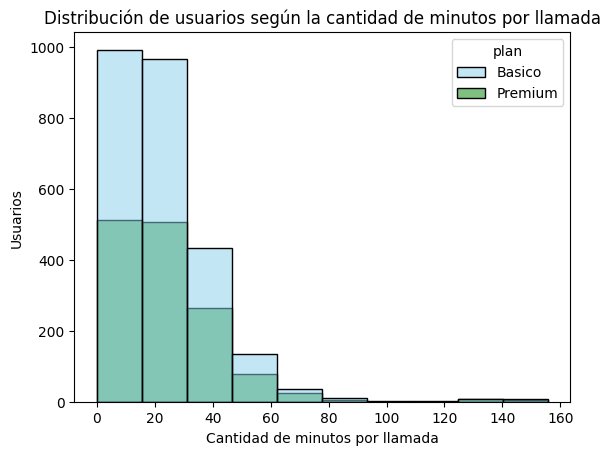

In [ ]:
# Histograma para visualizar la cant_minutos_llamada
sns.histplot(user_profile[['cant_minutos_llamada', 'plan']], bins=10, hue='plan', palette=['skyblue','green'], x='cant_minutos_llamada')
plt.xlabel('Cantidad de minutos por llamada')
plt.ylabel('Usuarios')
plt.title('Distribución de usuarios según la cantidad de minutos por llamada')
plt.show()

💡Insights:
- `Distribución de usuarios según la cantidad de minutos por llamada`:
Distribución fuertemente sesgada a la derecha, con una larga cola de valores altos. La mayoría de las llamadas son cortas y existen pocos casos de llamadas muy largas. La distribución es muy similar entre ambos planes. No se aprecian diferencias importantes en la duración de las llamadas. La duración de las llamadas es comparable entre los usuarios de ambos planes, lo que sugiere que el tipo de plan no modifica el tiempo promedio de conversación.

### 5.2 Identificación de Outliers

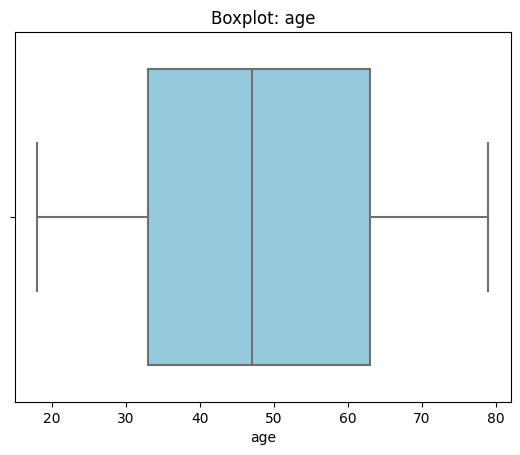

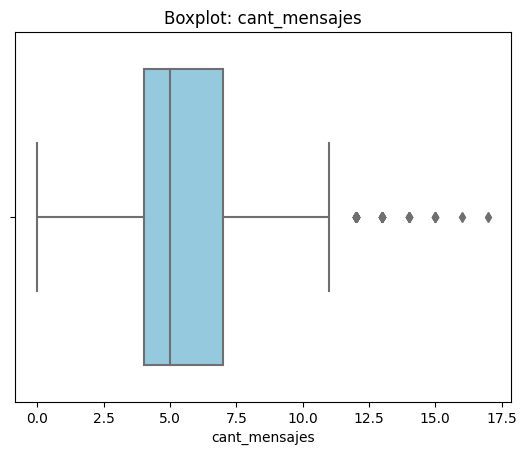

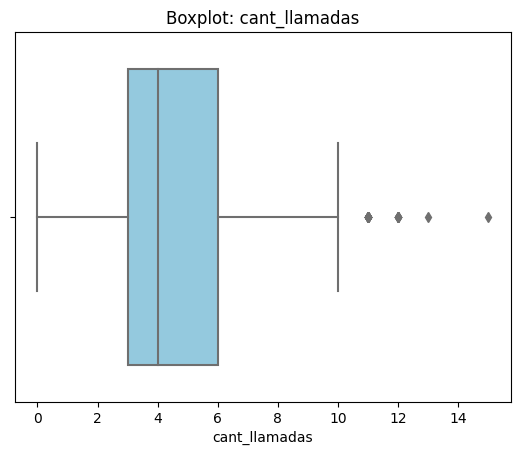

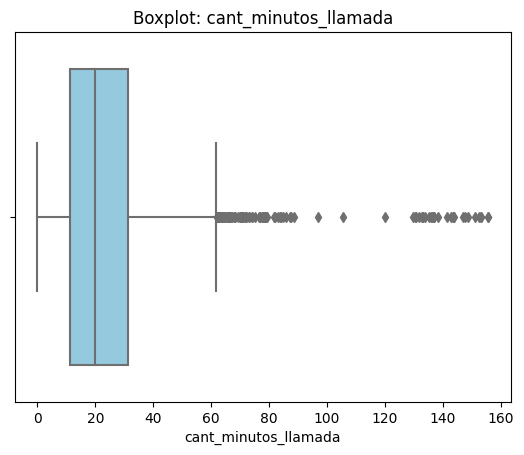

In [ ]:
# Visualizando usando BoxPlot
columnas_numericas = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_numericas:
    sns.boxplot(data=user_profile, x=col, color='skyblue')
    plt.title(f'Boxplot: {col}')
    plt.show()

💡Insights:
- `age`: No se observan puntos fuera de los límites del boxplot. La distribución es relativamente homogénea y las edades se encuentran dentro de un rango esperado (18–79 años). No requiere limpieza adicional.
- `cant_mensajes`: Sí, se identifican algunos usuarios con una cantidad de mensajes considerablemente superior al resto (aproximadamente entre 12 y 17 mensajes). Son pocos casos aislados. Mantener los valores y revisar únicamente si se sospecha de errores de captura. Es probable que correspondan a usuarios con un uso intensivo del servicio.
- `cant_llamadas`: Sí, se observan algunos valores extremos por encima del rango habitual (alrededor de 10 a 15 llamadas). La mayoría de los usuarios realiza entre 3 y 6 llamadas. Conservar los registros, ya que pueden representar clientes con un mayor nivel de actividad y no necesariamente errores en los datos.
- `cant_minutos_llamada`: Sí, en gran cantidad. La distribución presenta una fuerte asimetría positiva y una gran cantidad de valores extremos, con llamadas que alcanzan aproximadamente 160 minutos. Mantener los valores, pero realizar una revisión adicional para verificar que no existan errores de registro. Si corresponden a llamadas reales, forman parte del comportamiento esperado y no deben eliminarse.

In [ ]:
# Calcular límites con el método IQR
columnas_limites = ['cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_limites:
    Q1 = user_profile [col].quantile(0.25)
    Q3 = user_profile [col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    maximo = user_profile [col].max()
    print(f'=== {col} ===')
    print('Límite inferior:', lower)
    print('Límite superior:', upper)
    print ('Valor máximo:', maximo)


=== cant_mensajes ===
Límite inferior: -0.5
Límite superior: 11.5
Valor máximo: 17.0
=== cant_llamadas ===
Límite inferior: -1.5
Límite superior: 10.5
Valor máximo: 15.0
=== cant_minutos_llamada ===
Límite inferior: -19.322500000000005
Límite superior: 61.8575
Valor máximo: 155.69


In [ ]:
# Revisa los limites superiores y el max, para tomar la decisión de mantener los outliers o no
user_profile[columnas_limites].describe()

,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,3999.000000,3999.000000,3999.000000
mean,5.524381,4.478120,23.317054
std,2.358416,2.144238,18.168095
min,0.000000,0.000000,0.000000
25%,4.000000,3.000000,11.120000
50%,5.000000,4.000000,19.780000
75%,7.000000,6.000000,31.415000
max,17.000000,15.000000,155.690000


💡Insights:
- `cant_mensajes`: Sí (17 > 11.5). Mantener. Aunque existen algunos usuarios con una cantidad de mensajes superior al límite del IQR, el valor máximo (17) no es excesivamente alto y es totalmente plausible en un servicio de telecomunicaciones.
- `cant_llamadas`: Sí (15 > 10.5). Mantener. Los usuarios con más llamadas representan un comportamiento de uso intensivo, no un error evidente en los datos.
- `cant_minutos_llamada`: Sí (155.69 > 61.86). Mantener, con revisión. La distribución es naturalmente asimétrica hacia la derecha. Aunque existen llamadas muy largas, un máximo de 155.69 minutos (≈2 h 36 min) puede corresponder a casos reales. Solo sería necesario revisar estos registros para confirmar que no se trate de errores de captura.

---

## 🧩Paso 6: Segmentación de Clientes

### 6.1 Segmentación de Clientes Por Uso

In [ ]:
# Crear columna grupo_uso
condiciones = [
    (user_profile['cant_mensajes'] < 5) & (user_profile['cant_llamadas'] < 5),
    (user_profile['cant_mensajes'] < 10) & (user_profile['cant_llamadas'] < 10)
]
resultados = ['Bajo uso', 'Uso medio']

user_profile['grupo_uso'] = np.select(condiciones, resultados, default='Alto uso')

In [ ]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00+00:00,Basico,NaN,7.0,3.0,23.70,Uso medio
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619+00:00,Basico,NaN,5.0,10.0,33.18,Alto uso
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239+00:00,Basico,NaN,5.0,2.0,10.74,Uso medio
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858+00:00,Premium,NaN,11.0,3.0,8.99,Alto uso
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478+00:00,Basico,NaN,4.0,3.0,8.01,Bajo uso


### 6.2 Segmentación de Clientes Por Edad


In [ ]:
# Crear columna grupo_edad
condiciones = [
    user_profile['age'] < 30,
    user_profile['age'] < 60
]
resultados = ['Joven', 'Adulto']

user_profile['grupo_edad'] = np.select(condiciones, resultados, default='Adulto Mayor')

In [ ]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso,grupo_edad
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00+00:00,Basico,NaN,7.0,3.0,23.70,Uso medio,Adulto
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619+00:00,Basico,NaN,5.0,10.0,33.18,Alto uso,Adulto
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239+00:00,Basico,NaN,5.0,2.0,10.74,Uso medio,Adulto
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858+00:00,Premium,NaN,11.0,3.0,8.99,Alto uso,Adulto Mayor
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478+00:00,Basico,NaN,4.0,3.0,8.01,Bajo uso,Adulto Mayor


### 6.3 Visualización de la Segmentación de Clientes

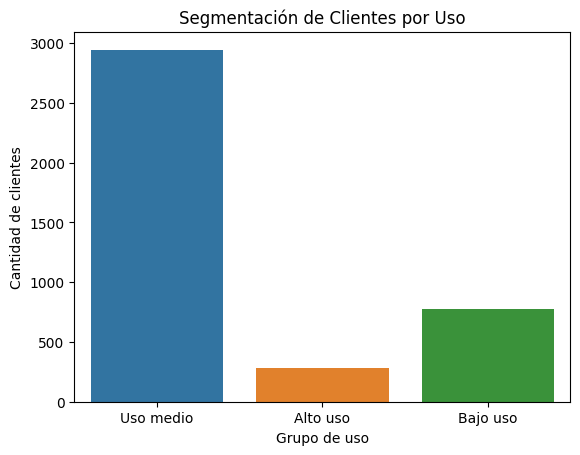

In [ ]:
# Visualización de los segmentos por uso
sns.countplot(data=user_profile, x='grupo_uso')
plt.title("Segmentación de Clientes por Uso")
plt.xlabel("Grupo de uso")
plt.ylabel("Cantidad de clientes")

plt.show()

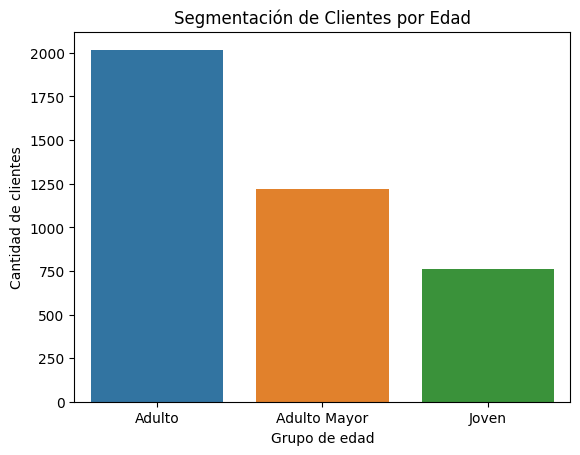

In [ ]:
# Visualización de los segmentos por edad
sns.countplot(data=user_profile, x='grupo_edad')
plt.title("Segmentación de Clientes por Edad")
plt.xlabel("Grupo de edad")
plt.ylabel("Cantidad de clientes")

plt.show()


---
## 🧩Paso 7: Insight Ejecutivo para Stakeholders

### Análisis ejecutivo

⚠️ **Problemas detectados en los datos**
- - Originalmente, el conjunto de datos presentaba valores nulos y un valor inválido (sentinel) que requerían revisión antes del análisis.
- La columna `city` tenía 469 valores nulos (11.73%) más 96 valores ?: 565 en total (14.1%). Recomendé imputar con la categoría "Desconocida" o excluirlos únicamente en análisis geográficos.
- `churn_date`, 3,534 valores nulos (88.35%). Sugerí mantenerlos, ya que representan clientes que continúan activos.
- `date`, 50 valores nulos (0.13%). Recomendé eliminarlos por ser un porcentaje mínimo y porque la fecha es indispensable para el análisis temporal.
- `duration`, 22,076 valores nulos (55.19%). Recomendé mantenerlos, ya que dependen del tipo de uso (type) y solo aplican a llamadas.
- `length`, 17,896 valores nulos (44.74%). Sugerí mantenerlos, ya que dependen del tipo de uso (type) y solo aplican a mensajes de texto.
- Y la columna `age` tenía valores inválidos (sentinel -999), los cuales reemplacé por la mediana.


🔍 **Segmentos por Edad**
- - La clasificación por grupos de edad mostró tres segmentos principales:
- Adultos: Es el grupo predominante dentro de la base de clientes.
- Adultos mayores: Representan el segundo segmento más numeroso.
- Jóvenes: Constituyen el grupo con menor cantidad de clientes.

- Comportamiento observado:
Los adultos concentran la mayor parte de los usuarios y, por lo tanto, representan el principal mercado de la empresa. No se observaron diferencias visuales importantes en los patrones de consumo entre las distintas edades ni entre los planes Básico y Premium, lo que sugiere que la edad, por sí sola, no determina un comportamiento de uso diferente.


📊 **Segmentos por Nivel de Uso**
- - Se distinguieron tres grupos de clientes:
- Usuarios de uso medio: Constituyen el segmento más numeroso de la base de datos. Estos clientes presentan un consumo equilibrado de llamadas y mensajes, por lo que representan el perfil típico de la empresa.
- Usuarios de bajo uso: Corresponden al segundo grupo en tamaño. Su actividad es reducida, lo que puede indicar clientes ocasionales o con necesidades limitadas de comunicación.
- Usuarios de alto uso: Representan el grupo más pequeño. Se caracterizan por realizar una mayor cantidad de llamadas, enviar más mensajes y, en algunos casos, acumular una mayor duración de llamadas.

- Comportamiento observado:
La mayor parte de la cartera de clientes mantiene un consumo moderado de los servicios. Los usuarios de alto uso constituyen un segmento estratégico, ya que tienen un mayor potencial para contratar planes con más beneficios o servicios adicionales.


➡️ Esto sugiere que la empresa cuenta con una base de clientes compuesta principalmente por adultos con un nivel de uso medio, mientras que los clientes de alto uso, aunque menos numerosos, representan una oportunidad importante para incrementar los ingresos mediante estrategias de fidelización y comercialización de planes de mayor valor. Por ello, una segmentación basada tanto en el nivel de uso como en la edad puede contribuir a diseñar campañas más efectivas y mejorar la rentabilidad del negocio. Complementariamente, el segmento de adultos merece una atención prioritaria por ser el grupo demográfico predominante, lo que maximiza el impacto de las acciones comerciales.

- Los outliers detectados representan patrones reales de uso intensivo y aportan información valiosa sobre el comportamiento de una parte de los clientes. Eliminarlos podría sesgar el análisis y ocultar oportunidades comerciales. Por ello, se conservaron en la base de datos y se consideran un segmento estratégico para acciones de retención, personalización de ofertas y maximización de ingresos.


💡 **Recomendaciones**
- Rediseñar el plan Premium para aumentar su atractivo:
Se observó que no existen diferencias importantes en los patrones de uso entre los clientes del plan Básico y Premium, lo que sugiere que el plan Premium no ofrece beneficios suficientemente diferenciadores. Recomiendo incrementar los beneficios del plan Premium (más minutos, mensajes ilimitados, datos adicionales o servicios exclusivos), e incorporar incentivos como atención prioritaria, roaming o descuentos en servicios complementarios.
- Crear un plan para usuarios de alto consumo:
El análisis identificó un grupo de clientes con un uso significativamente superior al promedio (más llamadas, más mensajes y mayor duración de llamadas). Recomiendo diseñar un plan "Premium Plus" o "Ilimitado" orientado a estos usuarios, e incluir minutos y mensajes ilimitados, junto con beneficios exclusivos.
- Implementar estrategias de upselling para usuarios de uso medio:
Los clientes de uso medio representan el segmento más numeroso y constituyen la mayor oportunidad de crecimiento. Recomiendo ofrecer promociones personalizadas para migrar del plan Básico al Premium, y cambios de plan cuando el consumo mensual se aproxime al límite del plan contratado.
- Crear planes segmentados según el perfil de consumo:
El análisis muestra que no todos los clientes utilizan los servicios de la misma manera. Recomiendo diseñar planes específicos, por ejemplo:
Plan Mensajería: para clientes que utilizan principalmente mensajes.
Plan Voz: para quienes realizan muchas llamadas o acumulan más minutos.
Plan Flexible: que permita adaptar mensualmente la cantidad de minutos o mensajes según el consumo.
– Diseñar campañas según la edad:
La mayoría de los clientes pertenece al segmento de adultos, mientras que jóvenes y adultos mayores representan grupos más pequeños. Recomiendo enfocar las campañas principales en adultos, ya que concentran la mayor parte de la cartera, y crear promociones específicas para jóvenes y adultos mayores, adaptadas a sus hábitos de consumo.

